## 1. Imports

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import random
from pathlib import Path
import json
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

## 2. Configurações gerais

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("../data")
IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
CSV_PATH = DATA_DIR / "GroundTruth.csv"

TEST_SIZE = 0.20

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
class_code = {label: idx for idx, label in enumerate(classes)}
class_name = {idx: label for label, idx in class_code.items()}

print(class_code)

{'MEL': 0, 'NV': 1, 'BCC': 2, 'AKIEC': 3, 'BKL': 4, 'DF': 5, 'VASC': 6}


## 3. Conferir arquivos `.keras` disponíveis

In [3]:
for file in os.listdir():
    if file.endswith(".keras"):
        print(file)

../models/transfer_learning/best_densenet169_dull_crop_oversampling.keras
../models/transfer_learning/encoder_decoder_segmenter.keras
../models/transfer_learning/segmented_densenet169_dull_smote_final.keras
../models/transfer_learning/deepsmote_autoencoder_64.keras
../models/transfer_learning/best_densenet169_dull_crop_smote.keras
../models/transfer_learning/best_deepskin_densenet169_undersampling.keras
../models/transfer_learning/efficientnetb4_crop_380_feature_extractor.keras
../models/transfer_learning/best_segmented_densenet169_dull_smote.keras
../models/transfer_learning/deepsmote_encoder_densenet201_crop.keras
../models/transfer_learning/best_efficientnetb4_crop_smote_380.keras
../models/transfer_learning/segmented_densenet169_feature_extractor.keras
../models/transfer_learning/deepsmote_autoencoder_densenet201_crop.keras
../models/transfer_learning/densenet201_crop_oversampling_320_final.keras
deepskin_densenet169_undersampling_final.keras
../models/transfer_learning/best_segmen

## 4. Configurações dos modelos

In [4]:
# Modelo A: DenseNet201 + Crop + SMOTE + 320x320
IMG_SIZE_A = (320, 320)
FEATURE_EXTRACTOR_A_PATH = "../models/transfer_learning/densenet201_crop_320_feature_extractor.keras"
CLASSIFIER_A_PATH = "../models/transfer_learning/best_densenet201_crop_oversampling_320.keras"

# Modelo B: DenseNet169 + Crop + SMOTE + 256x256
IMG_SIZE_B = (256, 256)
FEATURE_EXTRACTOR_B_PATH = "../models/transfer_learning/densenet169_dull_crop_feature_extractor.keras"
CLASSIFIER_B_PATH = "../models/transfer_learning/best_densenet169_dull_crop_oversampling.keras"

# Modelo C: EfficientNetB4 + Crop + SMOTE + 380x380
IMG_SIZE_C = (380, 380)
FEATURE_EXTRACTOR_C_PATH = "../models/transfer_learning/efficientnetb4_crop_380_feature_extractor.keras"
CLASSIFIER_C_PATH = "../models/transfer_learning/best_efficientnetb4_crop_oversampling_380.keras"

USE_DULL_RAZOR = False
USE_MASK_SEGMENTATION = False
USE_MASK_CROP = True
CROP_MARGIN = 20

WEIGHT_MODEL_A = 0.70
WEIGHT_MODEL_B = 0.20
WEIGHT_MODEL_C = 0.10

print("Modelo A:", IMG_SIZE_A, FEATURE_EXTRACTOR_A_PATH, CLASSIFIER_A_PATH)
print("Modelo B:", IMG_SIZE_B, FEATURE_EXTRACTOR_B_PATH, CLASSIFIER_B_PATH)
print("Modelo C:", IMG_SIZE_C, FEATURE_EXTRACTOR_C_PATH, CLASSIFIER_C_PATH)
print("Pesos:", WEIGHT_MODEL_A, WEIGHT_MODEL_B, WEIGHT_MODEL_C)

assert abs((WEIGHT_MODEL_A + WEIGHT_MODEL_B + WEIGHT_MODEL_C) - 1.0) < 1e-6, "Os pesos devem somar 1."

Modelo A: (320, 320) ../models/transfer_learning/densenet201_crop_320_feature_extractor.keras ../models/transfer_learning/best_densenet201_crop_oversampling_320.keras
Modelo B: (256, 256) ../models/transfer_learning/densenet169_dull_crop_feature_extractor.keras ../models/transfer_learning/best_densenet169_dull_crop_oversampling.keras
Modelo C: (380, 380) ../models/transfer_learning/efficientnetb4_crop_380_feature_extractor.keras ../models/transfer_learning/best_efficientnetb4_crop_oversampling_380.keras
Pesos: 0.7 0.2 0.1


## 5. Configurações do multi-crop/janelamento

In [5]:
LOCAL_CROP_RATIO = 0.90

INCLUDE_FULL_IMAGE = True

USE_HORIZONTAL_FLIP = True

USE_VERTICAL_FLIP = False

USE_HV_FLIP = False

print("LOCAL_CROP_RATIO:", LOCAL_CROP_RATIO)
print("INCLUDE_FULL_IMAGE:", INCLUDE_FULL_IMAGE)
print("USE_HORIZONTAL_FLIP:", USE_HORIZONTAL_FLIP)
print("USE_VERTICAL_FLIP:", USE_VERTICAL_FLIP)
print("USE_HV_FLIP:", USE_HV_FLIP)

LOCAL_CROP_RATIO: 0.9
INCLUDE_FULL_IMAGE: True
USE_HORIZONTAL_FLIP: True
USE_VERTICAL_FLIP: False
USE_HV_FLIP: False


## 6. Leitura do dataset e recriação do conjunto de teste

In [6]:
def find_image_path(image_id, images_dir):
    for ext in [".jpg", ".jpeg", ".png"]:
        path = images_dir / f"{image_id}{ext}"
        if path.exists():
            return str(path)
    return None


def find_mask_path(image_id, masks_dir):
    if not masks_dir.exists():
        return None

    candidates = [
        masks_dir / f"{image_id}_segmentation.png",
        masks_dir / f"{image_id}_segmentation.jpg",
        masks_dir / f"{image_id}_mask.png",
        masks_dir / f"{image_id}_mask.jpg",
        masks_dir / f"{image_id}.png",
        masks_dir / f"{image_id}.jpg",
    ]

    for path in candidates:
        if path.exists():
            return str(path)

    matches = list(masks_dir.glob(f"{image_id}*"))
    if len(matches) > 0:
        return str(matches[0])

    return None


metadata = pd.read_csv(CSV_PATH)

rows = []
for _, row in metadata.iterrows():
    image_id = str(row["image"])
    image_path = find_image_path(image_id, IMAGES_DIR)
    mask_path = find_mask_path(image_id, MASKS_DIR)

    if image_path is None:
        continue

    label_name = row[classes].idxmax()
    label = class_code[label_name]

    rows.append({
        "image": image_id,
        "image_path": image_path,
        "mask_path": mask_path,
        "class_name": label_name,
        "label": label
    })

df = pd.DataFrame(rows)

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df["label"]
)

print("Total de imagens:", len(df))
print("Teste:", len(test_df))
print("\nDistribuição do teste:")
print(test_df["class_name"].value_counts().reindex(classes))

Total de imagens: 10015
Teste: 2003

Distribuição do teste:
class_name
MEL       223
NV       1341
BCC       103
AKIEC      65
BKL       220
DF         23
VASC       28
Name: count, dtype: int64


## 7. Funções de pré-processamento

In [7]:
def read_rgb_image(path):
    if isinstance(path, bytes):
        path = path.decode("utf-8")

    image_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(f"Não foi possível carregar a imagem: {path}")

    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def dull_razor_remove_hair(image_rgb, kernel_size=(9, 9), threshold_value=10, inpaint_radius=6):
    image_rgb = image_rgb.astype(np.uint8)
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, kernel_size)
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    blackhat_blur = cv2.GaussianBlur(blackhat, (3, 3), 0)

    _, mask = cv2.threshold(blackhat_blur, threshold_value, 255, cv2.THRESH_BINARY)

    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    clean_bgr = cv2.inpaint(image_bgr, mask, inpaint_radius, cv2.INPAINT_TELEA)

    return cv2.cvtColor(clean_bgr, cv2.COLOR_BGR2RGB)


def read_binary_mask(mask_path, target_shape):
    if mask_path is None or pd.isna(mask_path):
        return None

    if isinstance(mask_path, bytes):
        mask_path = mask_path.decode("utf-8")

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return None

    height, width = target_shape[:2]
    mask = cv2.resize(mask, (width, height))

    return (mask > 127).astype(np.uint8)


def apply_mask_segmentation(image_rgb, mask_path):
    binary_mask = read_binary_mask(mask_path, target_shape=image_rgb.shape)

    if binary_mask is None:
        return image_rgb

    segmented = image_rgb * np.expand_dims(binary_mask, axis=-1)

    if np.mean(segmented) < 5:
        return image_rgb

    return segmented


def crop_lesion_with_margin(image_rgb, mask_path, margin=20):
    binary_mask = read_binary_mask(mask_path, target_shape=image_rgb.shape)

    if binary_mask is None:
        return image_rgb

    ys, xs = np.where(binary_mask > 0)

    if len(xs) == 0 or len(ys) == 0:
        return image_rgb

    height, width = image_rgb.shape[:2]

    x_min = max(xs.min() - margin, 0)
    x_max = min(xs.max() + margin, width - 1)
    y_min = max(ys.min() - margin, 0)
    y_max = min(ys.max() + margin, height - 1)

    cropped = image_rgb[y_min:y_max + 1, x_min:x_max + 1]

    if cropped.size == 0:
        return image_rgb

    return cropped


def preprocess_base_image(path, mask_path=None):
    image_rgb = read_rgb_image(path)

    if USE_DULL_RAZOR:
        image_rgb = dull_razor_remove_hair(image_rgb)

    if USE_MASK_CROP:
        image_rgb = crop_lesion_with_margin(image_rgb, mask_path, margin=CROP_MARGIN)
    elif USE_MASK_SEGMENTATION:
        image_rgb = apply_mask_segmentation(image_rgb, mask_path)

    return image_rgb.astype("float32")

## 8. Função de multi-crop/janelamento

In [8]:
def generate_multicrop_images_from_base(
    image_rgb,
    target_size,
    local_crop_ratio=0.80,
    include_full=True,
    use_horizontal_flip=True,
    use_vertical_flip=False,
    use_hv_flip=False
):
    image_rgb = image_rgb.astype("float32")
    h, w = image_rgb.shape[:2]

    crops = []

    if include_full:
        crops.append(cv2.resize(image_rgb, target_size))

    crop_h = int(h * local_crop_ratio)
    crop_w = int(w * local_crop_ratio)

    crop_h = max(1, min(crop_h, h))
    crop_w = max(1, min(crop_w, w))

    positions = [
        (0, 0),
        (0, w - crop_w),
        (h - crop_h, 0),
        (h - crop_h, w - crop_w),
        ((h - crop_h) // 2, (w - crop_w) // 2),
    ]

    for y, x in positions:
        y = max(0, int(y))
        x = max(0, int(x))

        crop = image_rgb[y:y + crop_h, x:x + crop_w]

        if crop.size == 0:
            continue

        crop = cv2.resize(crop, target_size)
        crops.append(crop)

    augmented = []

    for crop in crops:
        augmented.append(crop)

        if use_horizontal_flip:
            augmented.append(np.fliplr(crop))

        if use_vertical_flip:
            augmented.append(np.flipud(crop))

        if use_hv_flip:
            augmented.append(np.flipud(np.fliplr(crop)))

    return np.array(augmented, dtype="float32")

## 9. Visualizar janelas geradas

Quantidade de imagens geradas: 12
Shape: (12, 320, 320, 3)


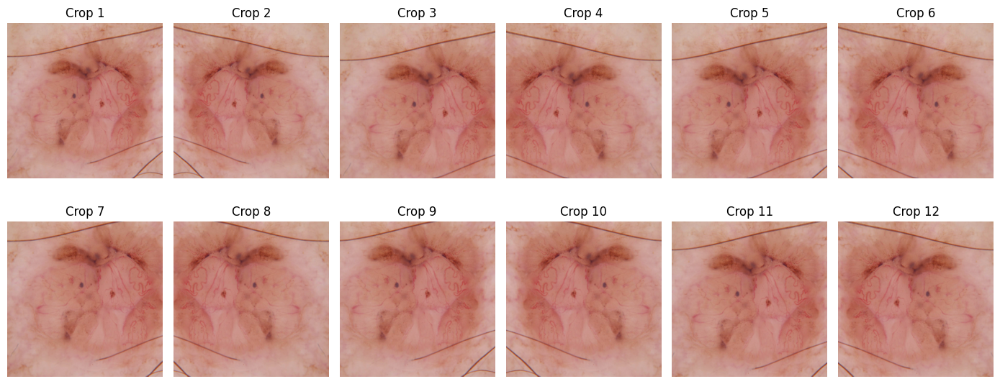

In [9]:
sample_row = test_df.sample(1, random_state=SEED).iloc[0]

base_img = preprocess_base_image(sample_row["image_path"], sample_row["mask_path"])

windows = generate_multicrop_images_from_base(
    base_img,
    target_size=IMG_SIZE_A,
    local_crop_ratio=LOCAL_CROP_RATIO,
    include_full=INCLUDE_FULL_IMAGE,
    use_horizontal_flip=USE_HORIZONTAL_FLIP,
    use_vertical_flip=USE_VERTICAL_FLIP,
    use_hv_flip=USE_HV_FLIP
)

print("Quantidade de imagens geradas:", len(windows))
print("Shape:", windows.shape)

n_show = min(len(windows), 12)

plt.figure(figsize=(14, 6))

for i in range(n_show):
    plt.subplot(2, 6, i + 1)
    plt.imshow(np.clip(windows[i], 0, 255).astype("uint8"))
    plt.title(f"Crop {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("../results/figures/ensembles/exemplo_multicrop_tta.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Carregar modelos

In [10]:
feature_extractor_a = keras.models.load_model(FEATURE_EXTRACTOR_A_PATH)
classifier_a = keras.models.load_model(CLASSIFIER_A_PATH)

feature_extractor_b = keras.models.load_model(FEATURE_EXTRACTOR_B_PATH)
classifier_b = keras.models.load_model(CLASSIFIER_B_PATH)

feature_extractor_c = keras.models.load_model(FEATURE_EXTRACTOR_C_PATH)
classifier_c = keras.models.load_model(CLASSIFIER_C_PATH)

print("Modelo A input:", feature_extractor_a.input_shape)
print("Modelo B input:", feature_extractor_b.input_shape)
print("Modelo C input:", feature_extractor_c.input_shape)

Modelo A input: (None, 320, 320, 3)
Modelo B input: (None, 256, 256, 3)
Modelo C input: (None, 380, 380, 3)


## 11. Predição com multi-crop TTA

In [11]:
def predict_model_with_multicrop_tta(
    image_path,
    mask_path,
    img_size,
    feature_extractor,
    classifier
):
    base_img = preprocess_base_image(image_path, mask_path)

    tta_images = generate_multicrop_images_from_base(
        base_img,
        target_size=img_size,
        local_crop_ratio=LOCAL_CROP_RATIO,
        include_full=INCLUDE_FULL_IMAGE,
        use_horizontal_flip=USE_HORIZONTAL_FLIP,
        use_vertical_flip=USE_VERTICAL_FLIP,
        use_hv_flip=USE_HV_FLIP
    )

    features = feature_extractor.predict(tta_images, verbose=0)
    preds = classifier.predict(features, verbose=0)

    return np.mean(preds, axis=0)


def predict_ensemble_multicrop_tta(image_path, mask_path):
    pred_a = predict_model_with_multicrop_tta(
        image_path=image_path,
        mask_path=mask_path,
        img_size=IMG_SIZE_A,
        feature_extractor=feature_extractor_a,
        classifier=classifier_a
    )

    pred_b = predict_model_with_multicrop_tta(
        image_path=image_path,
        mask_path=mask_path,
        img_size=IMG_SIZE_B,
        feature_extractor=feature_extractor_b,
        classifier=classifier_b
    )

    pred_c = predict_model_with_multicrop_tta(
        image_path=image_path,
        mask_path=mask_path,
        img_size=IMG_SIZE_C,
        feature_extractor=feature_extractor_c,
        classifier=classifier_c
    )

    final_pred = (
        (WEIGHT_MODEL_A * pred_a) +
        (WEIGHT_MODEL_B * pred_b) +
        (WEIGHT_MODEL_C * pred_c)
    )

    return final_pred

## 12. Teste rápido em uma imagem

In [12]:
sample_row = test_df.iloc[0]

sample_pred = predict_ensemble_multicrop_tta(
    sample_row["image_path"],
    sample_row["mask_path"]
)

print("Shape da predição:", sample_pred.shape)
print("Soma:", sample_pred.sum())
print("Classe real:", sample_row["class_name"])
print("Classe predita:", class_name[int(np.argmax(sample_pred))])

Shape da predição: (7,)
Soma: 1.0
Classe real: NV
Classe predita: NV


## 13. Avaliação no conjunto de teste

In [13]:
y_true_multicrop = []
y_pred_multicrop = []
y_prob_multicrop = []

for idx, row in test_df.reset_index(drop=True).iterrows():
    pred = predict_ensemble_multicrop_tta(row["image_path"], row["mask_path"])
    pred_class = int(np.argmax(pred))

    y_true_multicrop.append(int(row["label"]))
    y_pred_multicrop.append(pred_class)
    y_prob_multicrop.append(pred)

    if (idx + 1) % 50 == 0:
        print(f"Avaliadas {idx + 1}/{len(test_df)} imagens")

y_true_multicrop = np.array(y_true_multicrop)
y_pred_multicrop = np.array(y_pred_multicrop)
y_prob_multicrop = np.array(y_prob_multicrop, dtype="float32")

print("Avaliação com multi-crop TTA concluída.")
print("Shape das probabilidades:", y_prob_multicrop.shape)


Avaliadas 50/2003 imagens
Avaliadas 100/2003 imagens
Avaliadas 150/2003 imagens
Avaliadas 200/2003 imagens
Avaliadas 250/2003 imagens
Avaliadas 300/2003 imagens
Avaliadas 350/2003 imagens
Avaliadas 400/2003 imagens
Avaliadas 450/2003 imagens
Avaliadas 500/2003 imagens
Avaliadas 550/2003 imagens
Avaliadas 600/2003 imagens
Avaliadas 650/2003 imagens
Avaliadas 700/2003 imagens
Avaliadas 750/2003 imagens
Avaliadas 800/2003 imagens
Avaliadas 850/2003 imagens
Avaliadas 900/2003 imagens
Avaliadas 950/2003 imagens
Avaliadas 1000/2003 imagens
Avaliadas 1050/2003 imagens
Avaliadas 1100/2003 imagens
Avaliadas 1150/2003 imagens
Avaliadas 1200/2003 imagens
Avaliadas 1250/2003 imagens
Avaliadas 1300/2003 imagens
Avaliadas 1350/2003 imagens
Avaliadas 1400/2003 imagens
Avaliadas 1450/2003 imagens
Avaliadas 1500/2003 imagens
Avaliadas 1550/2003 imagens
Avaliadas 1600/2003 imagens
Avaliadas 1650/2003 imagens
Avaliadas 1700/2003 imagens
Avaliadas 1750/2003 imagens
Avaliadas 1800/2003 imagens
Avaliadas 18

## 14. Relatório de classificação

In [14]:
print("Relatório de Classificação do Ensemble com Multi-Crop TTA:")
print(classification_report(
    y_true_multicrop,
    y_pred_multicrop,
    target_names=classes,
    digits=4,
    zero_division=0
))

acc_multicrop = accuracy_score(y_true_multicrop, y_pred_multicrop)

macro_precision_multicrop = precision_score(y_true_multicrop, y_pred_multicrop, average="macro", zero_division=0)
macro_recall_multicrop = recall_score(y_true_multicrop, y_pred_multicrop, average="macro", zero_division=0)
macro_f1_multicrop = f1_score(y_true_multicrop, y_pred_multicrop, average="macro", zero_division=0)

weighted_precision_multicrop = precision_score(y_true_multicrop, y_pred_multicrop, average="weighted", zero_division=0)
weighted_recall_multicrop = recall_score(y_true_multicrop, y_pred_multicrop, average="weighted", zero_division=0)
weighted_f1_multicrop = f1_score(y_true_multicrop, y_pred_multicrop, average="weighted", zero_division=0)

print("\nMÉTRICAS GERAIS DO ENSEMBLE COM MULTI-CROP TTA")
print(f"Accuracy: {acc_multicrop:.4f}")

print("\nMacro Average:")
print(f"  Precision: {macro_precision_multicrop:.4f}")
print(f"  Recall: {macro_recall_multicrop:.4f}")
print(f"  F1-Score: {macro_f1_multicrop:.4f}")

print("\nWeighted Average:")
print(f"  Precision: {weighted_precision_multicrop:.4f}")
print(f"  Recall: {weighted_recall_multicrop:.4f}")
print(f"  F1-Score: {weighted_f1_multicrop:.4f}")

Relatório de Classificação do Ensemble com Multi-Crop TTA:
              precision    recall  f1-score   support

         MEL     0.7853    0.6726    0.7246       223
          NV     0.9302    0.9635    0.9465      1341
         BCC     0.7727    0.8252    0.7981       103
       AKIEC     0.6774    0.6462    0.6614        65
         BKL     0.7761    0.7091    0.7411       220
          DF     0.9524    0.8696    0.9091        23
        VASC     0.8966    0.9286    0.9123        28

    accuracy                         0.8842      2003
   macro avg     0.8272    0.8021    0.8133      2003
weighted avg     0.8806    0.8842    0.8815      2003


MÉTRICAS GERAIS DO ENSEMBLE COM MULTI-CROP TTA
Accuracy: 0.8842

Macro Average:
  Precision: 0.8272
  Recall: 0.8021
  F1-Score: 0.8133

Weighted Average:
  Precision: 0.8806
  Recall: 0.8842
  F1-Score: 0.8815


## 15. Matriz de confusão em porcentagem

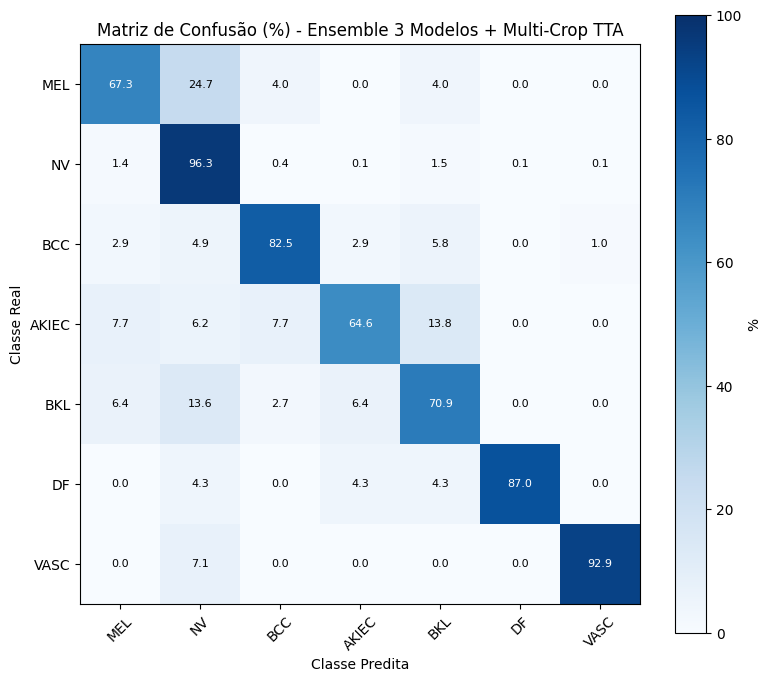

In [15]:
cm_multicrop = confusion_matrix(y_true_multicrop, y_pred_multicrop, labels=list(range(len(classes))))
cm_percent_multicrop = cm_multicrop.astype("float") / cm_multicrop.sum(axis=1, keepdims=True) * 100
cm_percent_multicrop = np.nan_to_num(cm_percent_multicrop)

plt.figure(figsize=(8, 7))
im = plt.imshow(cm_percent_multicrop, interpolation="nearest", cmap="Blues", vmin=0, vmax=100)

plt.title("Matriz de Confusão (%) - Ensemble 3 Modelos + Multi-Crop TTA")
plt.colorbar(im, label="%")

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

for i in range(cm_percent_multicrop.shape[0]):
    for j in range(cm_percent_multicrop.shape[1]):
        color = "white" if cm_percent_multicrop[i, j] > 50 else "black"
        plt.text(j, i, f"{cm_percent_multicrop[i, j]:.1f}", ha="center", va="center", color=color, fontsize=8)

plt.ylabel("Classe Real")
plt.xlabel("Classe Predita")
plt.tight_layout()
plt.savefig("../results/figures/ensembles/matriz_confusao_percent_ensemble_3_modelos_multicrop_tta.png", dpi=300, bbox_inches="tight")
plt.show()

## 16. Comparação com o melhor ensemble anterior

In [16]:
print("Melhor ensemble anterior com TTA tradicional:")
print("DenseNet201/DenseNet169/EfficientNetB4 + TTA")
print("Pesos: 0.60 / 0.30 / 0.10")
print("Accuracy: 0.8832")
print("F1 macro: 0.8217")
print("F1 ponderado: 0.8800")

print("\nResultado com Multi-Crop TTA:")
print(f"Accuracy: {acc_multicrop:.4f}")
print(f"F1 macro: {macro_f1_multicrop:.4f}")
print(f"F1 ponderado: {weighted_f1_multicrop:.4f}")

print("\nConfiguração:")
print("LOCAL_CROP_RATIO:", LOCAL_CROP_RATIO)
print("INCLUDE_FULL_IMAGE:", INCLUDE_FULL_IMAGE)
print("USE_HORIZONTAL_FLIP:", USE_HORIZONTAL_FLIP)
print("USE_VERTICAL_FLIP:", USE_VERTICAL_FLIP)
print("USE_HV_FLIP:", USE_HV_FLIP)
print("Pesos:", WEIGHT_MODEL_A, WEIGHT_MODEL_B, WEIGHT_MODEL_C)

Melhor ensemble anterior com TTA tradicional:
DenseNet201/DenseNet169/EfficientNetB4 + TTA
Pesos: 0.60 / 0.30 / 0.10
Accuracy: 0.8832
F1 macro: 0.8217
F1 ponderado: 0.8800

Resultado com Multi-Crop TTA:
Accuracy: 0.8842
F1 macro: 0.8133
F1 ponderado: 0.8815

Configuração:
LOCAL_CROP_RATIO: 0.9
INCLUDE_FULL_IMAGE: True
USE_HORIZONTAL_FLIP: True
USE_VERTICAL_FLIP: False
USE_HV_FLIP: False
Pesos: 0.7 0.2 0.1


## 17. Salvar resultados

In [17]:
EXPERIMENT_NAME = (
    f"ensemble_3_modelos_multicrop_ratio{LOCAL_CROP_RATIO}_"
    f"A{WEIGHT_MODEL_A}_B{WEIGHT_MODEL_B}_C{WEIGHT_MODEL_C}"
).replace(".", "p")

RESULTS_DIR = Path("../results/ensembles/resultados_multicrop_tta")
RESULTS_DIR.mkdir(exist_ok=True)

predictions_df = test_df.reset_index(drop=True).copy()
predictions_df["y_true"] = y_true_multicrop
predictions_df["y_pred"] = y_pred_multicrop
predictions_df["class_true"] = [class_name[int(label)] for label in y_true_multicrop]
predictions_df["class_pred"] = [class_name[int(label)] for label in y_pred_multicrop]
predictions_df["correct"] = predictions_df["y_true"] == predictions_df["y_pred"]

predictions_path = RESULTS_DIR / f"{EXPERIMENT_NAME}_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

metrics = {
    "experiment_name": EXPERIMENT_NAME,
    "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "configuration": {
        "model_a": {
            "name": "DenseNet201 + Crop + SMOTE",
            "img_size": IMG_SIZE_A,
            "feature_extractor": FEATURE_EXTRACTOR_A_PATH,
            "classifier": CLASSIFIER_A_PATH,
            "weight": WEIGHT_MODEL_A
        },
        "model_b": {
            "name": "DenseNet169 + Crop + SMOTE",
            "img_size": IMG_SIZE_B,
            "feature_extractor": FEATURE_EXTRACTOR_B_PATH,
            "classifier": CLASSIFIER_B_PATH,
            "weight": WEIGHT_MODEL_B
        },
        "model_c": {
            "name": "EfficientNetB4 + Crop + SMOTE",
            "img_size": IMG_SIZE_C,
            "feature_extractor": FEATURE_EXTRACTOR_C_PATH,
            "classifier": CLASSIFIER_C_PATH,
            "weight": WEIGHT_MODEL_C
        },
        "use_dull_razor": USE_DULL_RAZOR,
        "use_mask_segmentation": USE_MASK_SEGMENTATION,
        "use_mask_crop": USE_MASK_CROP,
        "crop_margin": CROP_MARGIN,
        "multicrop_tta": True,
        "local_crop_ratio": LOCAL_CROP_RATIO,
        "include_full_image": INCLUDE_FULL_IMAGE,
        "use_horizontal_flip": USE_HORIZONTAL_FLIP,
        "use_vertical_flip": USE_VERTICAL_FLIP,
        "use_hv_flip": USE_HV_FLIP
    },
    "metrics": {
        "accuracy": float(acc_multicrop),
        "macro_precision": float(macro_precision_multicrop),
        "macro_recall": float(macro_recall_multicrop),
        "macro_f1": float(macro_f1_multicrop),
        "weighted_precision": float(weighted_precision_multicrop),
        "weighted_recall": float(weighted_recall_multicrop),
        "weighted_f1": float(weighted_f1_multicrop)
    }
}

metrics_path = RESULTS_DIR / f"{EXPERIMENT_NAME}_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4, ensure_ascii=False)

cm_path = RESULTS_DIR / f"{EXPERIMENT_NAME}_confusion_matrix_percent.csv"
pd.DataFrame(cm_percent_multicrop, index=classes, columns=classes).to_csv(cm_path)

print("Resultados salvos com sucesso:")
print("Predições:", predictions_path)
print("Métricas:", metrics_path)
print("Matriz de confusão:", cm_path)

Resultados salvos com sucesso:
Predições: resultados_multicrop_tta/ensemble_3_modelos_multicrop_ratio0p9_A0p7_B0p2_C0p1_predictions.csv
Métricas: resultados_multicrop_tta/ensemble_3_modelos_multicrop_ratio0p9_A0p7_B0p2_C0p1_metrics.json
Matriz de confusão: resultados_multicrop_tta/ensemble_3_modelos_multicrop_ratio0p9_A0p7_B0p2_C0p1_confusion_matrix_percent.csv


## 18. Grad-CAM — configuração

Esta seção gera Grad-CAM no formato solicitado:

```text
Original image | Grad-CAM map | Result
```

Serão exibidos:

- uma imagem correta para cada classe, quando existir;
- uma imagem para cada tipo de erro encontrado, considerando o par `true class → predicted class`.


In [18]:
import matplotlib.cm as cm

# Quantidade máxima de exemplos por classe correta.
N_CORRECT_PER_CLASS = 1

# Quantidade máxima de exemplos por par de erro: classe real -> classe predita.
N_ERROR_PER_PAIR = 1

# Transparência do Grad-CAM sobre a imagem original.
GRADCAM_ALPHA = 0.45

print("N_CORRECT_PER_CLASS:", N_CORRECT_PER_CLASS)
print("N_ERROR_PER_PAIR:", N_ERROR_PER_PAIR)
print("GRADCAM_ALPHA:", GRADCAM_ALPHA)


N_CORRECT_PER_CLASS: 1
N_ERROR_PER_PAIR: 1
GRADCAM_ALPHA: 0.45


## 19. Funções auxiliares do Grad-CAM para o ensemble


In [20]:
def find_last_conv_layer(model):
    """
    Procura recursivamente a última camada convolucional dentro do modelo.
    Funciona mesmo quando a DenseNet/EfficientNet está aninhada dentro de outro modelo.
    """
    conv_types = (
        keras.layers.Conv2D,
        keras.layers.SeparableConv2D,
        keras.layers.DepthwiseConv2D,
    )

    last_conv_layer = None

    def search_layers(layer):
        nonlocal last_conv_layer

        if isinstance(layer, conv_types):
            last_conv_layer = layer

        # Caso a camada seja um modelo aninhado, busca dentro dela também
        if hasattr(layer, "layers"):
            for sub_layer in layer.layers:
                search_layers(sub_layer)

    search_layers(model)

    if last_conv_layer is None:
        raise ValueError(
            "No convolutional layer was found in the model. "
            "Check if the feature extractor really contains DenseNet/EfficientNet convolutional layers."
        )

    return last_conv_layer


def print_model_layers(model, model_name):
    print(f"\nCamadas principais de {model_name}:")
    for layer in model.layers:
        print(layer.name, type(layer).__name__)


print_model_layers(feature_extractor_a, "feature_extractor_a")
print_model_layers(feature_extractor_b, "feature_extractor_b")
print_model_layers(feature_extractor_c, "feature_extractor_c")


LAST_CONV_LAYER_A = find_last_conv_layer(feature_extractor_a)
LAST_CONV_LAYER_B = find_last_conv_layer(feature_extractor_b)
LAST_CONV_LAYER_C = find_last_conv_layer(feature_extractor_c)

LAST_CONV_A = LAST_CONV_LAYER_A.name
LAST_CONV_B = LAST_CONV_LAYER_B.name
LAST_CONV_C = LAST_CONV_LAYER_C.name

print("\nÚltima camada convolucional encontrada:")
print("Model A:", LAST_CONV_A)
print("Model B:", LAST_CONV_B)
print("Model C:", LAST_CONV_C)


def build_gradcam_model(feature_extractor, classifier, last_conv_layer):
    """
    Cria um modelo que retorna:
    1. saída da última camada convolucional
    2. saída final do classificador
    """
    grad_model = keras.Model(
        inputs=feature_extractor.input,
        outputs=[
            last_conv_layer.output,
            classifier(feature_extractor.output)
        ]
    )

    return grad_model


gradcam_model_a = build_gradcam_model(
    feature_extractor=feature_extractor_a,
    classifier=classifier_a,
    last_conv_layer=LAST_CONV_LAYER_A
)

gradcam_model_b = build_gradcam_model(
    feature_extractor=feature_extractor_b,
    classifier=classifier_b,
    last_conv_layer=LAST_CONV_LAYER_B
)

gradcam_model_c = build_gradcam_model(
    feature_extractor=feature_extractor_c,
    classifier=classifier_c,
    last_conv_layer=LAST_CONV_LAYER_C
)

print("\nModelos Grad-CAM criados com sucesso.")


Camadas principais de feature_extractor_a:
input_layer InputLayer
densenet201 Functional
global_average_pooling2d GlobalAveragePooling2D

Camadas principais de feature_extractor_b:
input_layer InputLayer
densenet169 Functional
global_average_pooling2d GlobalAveragePooling2D

Camadas principais de feature_extractor_c:
input_layer InputLayer
efficientnetb4 Functional
global_average_pooling2d GlobalAveragePooling2D

Última camada convolucional encontrada:
Model A: conv5_block32_2_conv
Model B: conv5_block32_2_conv
Model C: top_conv

Modelos Grad-CAM criados com sucesso.


## 20. Selecionar exemplos: acertos por classe e erros por caso


In [21]:
gradcam_eval_df = test_df.reset_index(drop=True).copy()
gradcam_eval_df["y_true"] = y_true_multicrop
gradcam_eval_df["y_pred"] = y_pred_multicrop
gradcam_eval_df["true_class"] = [class_name[int(label)] for label in y_true_multicrop]
gradcam_eval_df["pred_class"] = [class_name[int(label)] for label in y_pred_multicrop]
gradcam_eval_df["correct"] = gradcam_eval_df["y_true"] == gradcam_eval_df["y_pred"]

for class_idx, class_label in enumerate(classes):
    gradcam_eval_df[f"prob_{class_label}"] = y_prob_multicrop[:, class_idx]

correct_samples = []

for class_idx, class_label in enumerate(classes):
    idxs = gradcam_eval_df.index[
        (gradcam_eval_df["y_true"] == class_idx) &
        (gradcam_eval_df["y_pred"] == class_idx)
    ].tolist()

    for idx in idxs[:N_CORRECT_PER_CLASS]:
        correct_samples.append({
            "idx": idx,
            "group": "correct",
            "case_label": f"Correct {class_label}",
            "title_color": "green"
        })

error_samples = []

error_pairs = (
    gradcam_eval_df[~gradcam_eval_df["correct"]]
    .groupby(["y_true", "y_pred"])
    .size()
    .reset_index(name="count")
    .sort_values(["y_true", "y_pred"])
)

for _, pair in error_pairs.iterrows():
    true_idx = int(pair["y_true"])
    pred_idx = int(pair["y_pred"])

    idxs = gradcam_eval_df.index[
        (gradcam_eval_df["y_true"] == true_idx) &
        (gradcam_eval_df["y_pred"] == pred_idx)
    ].tolist()

    for idx in idxs[:N_ERROR_PER_PAIR]:
        error_samples.append({
            "idx": idx,
            "group": "error",
            "case_label": f"Error: {class_name[true_idx]} → {class_name[pred_idx]}",
            "title_color": "red"
        })

print("Correct examples selected:", len(correct_samples))
for item in correct_samples:
    row = gradcam_eval_df.iloc[item["idx"]]
    print(f"- {item['case_label']} | index={item['idx']} | true={row['true_class']} | pred={row['pred_class']}")

print("\nError examples selected:", len(error_samples))
for item in error_samples:
    row = gradcam_eval_df.iloc[item["idx"]]
    print(f"- {item['case_label']} | index={item['idx']} | true={row['true_class']} | pred={row['pred_class']}")


Correct examples selected: 7
- Correct MEL | index=20 | true=MEL | pred=MEL
- Correct NV | index=0 | true=NV | pred=NV
- Correct BCC | index=5 | true=BCC | pred=BCC
- Correct AKIEC | index=29 | true=AKIEC | pred=AKIEC
- Correct BKL | index=6 | true=BKL | pred=BKL
- Correct DF | index=145 | true=DF | pred=DF
- Correct VASC | index=11 | true=VASC | pred=VASC

Error examples selected: 26
- Error: MEL → NV | index=10 | true=MEL | pred=NV
- Error: MEL → BCC | index=87 | true=MEL | pred=BCC
- Error: MEL → BKL | index=16 | true=MEL | pred=BKL
- Error: NV → MEL | index=31 | true=NV | pred=MEL
- Error: NV → BCC | index=82 | true=NV | pred=BCC
- Error: NV → AKIEC | index=1551 | true=NV | pred=AKIEC
- Error: NV → BKL | index=100 | true=NV | pred=BKL
- Error: NV → DF | index=1182 | true=NV | pred=DF
- Error: NV → VASC | index=45 | true=NV | pred=VASC
- Error: BCC → MEL | index=354 | true=BCC | pred=MEL
- Error: BCC → NV | index=143 | true=BCC | pred=NV
- Error: BCC → AKIEC | index=446 | true=BCC |

## 21. Plotar Grad-CAM no formato: Original image | Grad-CAM map | Result


model_a connected feature map: densenet201/relu (None, 10, 10, 1920)
model_b connected feature map: densenet169/relu (None, 8, 8, 1664)
model_c connected feature map: efficientnetb4/top_activation (None, 12, 12, 1792)
Grad-CAM functions loaded successfully.
make_ensemble_gradcam_heatmap: True


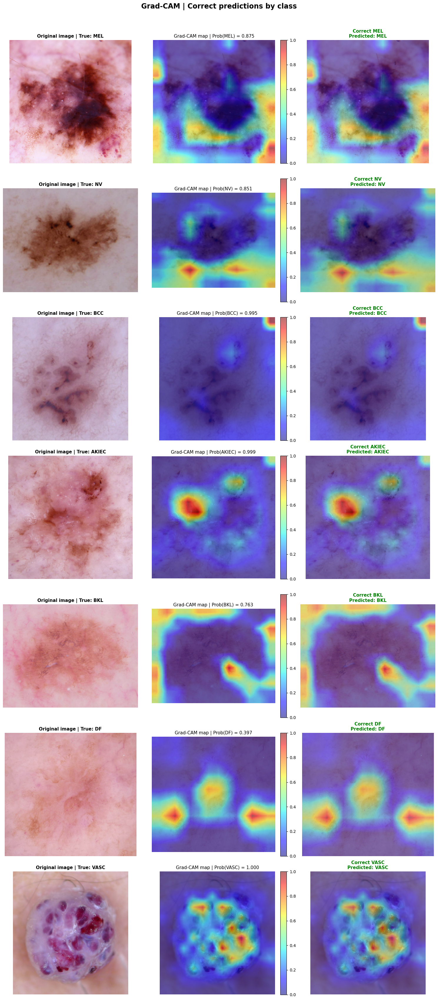




In [24]:
import matplotlib.cm as cm

N_CORRECT_PER_CLASS = 1
N_ERROR_PER_PAIR = 1
GRADCAM_ALPHA = 0.45


def find_last_4d_layer_in_nested_model(model):
    """
    Encontra a última camada com saída 4D dentro de um modelo,
    incluindo modelos aninhados como DenseNet/EfficientNet.
    """
    last_layer = None

    for layer in model.layers:
        try:
            if hasattr(layer.output, "shape") and len(layer.output.shape) == 4:
                last_layer = layer
        except Exception:
            pass

        if hasattr(layer, "layers"):
            nested_last = find_last_4d_layer_in_nested_model(layer)
            if nested_last is not None:
                last_layer = nested_last

    return last_layer


def build_connected_gradcam_model(feature_extractor, classifier, model_name):
    """
    Reconstrói o feature_extractor em um novo grafo funcional.

    Isso evita o erro de KeyError quando a última camada convolucional está
    dentro de um modelo aninhado, como DenseNet ou EfficientNet.
    """
    inputs = keras.Input(shape=feature_extractor.input_shape[1:])
    x = inputs
    conv_output = None
    conv_name = None

    for layer in feature_extractor.layers:
        if isinstance(layer, keras.layers.InputLayer):
            continue

        # Caso a camada seja um modelo aninhado, como DenseNet/EfficientNet
        if hasattr(layer, "layers") and len(layer.layers) > 0:
            last_4d_layer = find_last_4d_layer_in_nested_model(layer)

            if last_4d_layer is not None:
                nested_model = keras.Model(
                    inputs=layer.input,
                    outputs=[last_4d_layer.output, layer.output],
                    name=f"{model_name}_nested_gradcam"
                )

                conv_output, x = nested_model(x)
                conv_name = f"{layer.name}/{last_4d_layer.name}"
            else:
                x = layer(x)

        else:
            x = layer(x)

            try:
                if hasattr(x, "shape") and len(x.shape) == 4:
                    conv_output = x
                    conv_name = layer.name
            except Exception:
                pass

    if conv_output is None:
        raise ValueError(
            f"No connected 4D feature map was found for {model_name}. "
            "This feature extractor may have been saved after pooling."
        )

    predictions = classifier(x)

    grad_model = keras.Model(
        inputs=inputs,
        outputs=[conv_output, predictions],
        name=f"gradcam_{model_name}"
    )

    print(f"{model_name} connected feature map:", conv_name, conv_output.shape)

    return grad_model


gradcam_model_a = build_connected_gradcam_model(
    feature_extractor=feature_extractor_a,
    classifier=classifier_a,
    model_name="model_a"
)

gradcam_model_b = build_connected_gradcam_model(
    feature_extractor=feature_extractor_b,
    classifier=classifier_b,
    model_name="model_b"
)

gradcam_model_c = build_connected_gradcam_model(
    feature_extractor=feature_extractor_c,
    classifier=classifier_c,
    model_name="model_c"
)


def normalize_heatmap(heatmap):
    heatmap = np.maximum(heatmap, 0)
    max_value = np.max(heatmap)

    if max_value <= 1e-8:
        return np.zeros_like(heatmap, dtype="float32")

    return (heatmap / max_value).astype("float32")


def make_gradcam_heatmap_single_model(
    image_rgb,
    target_size,
    grad_model,
    class_index
):
    resized = cv2.resize(image_rgb.astype("float32"), target_size)
    img_tensor = tf.convert_to_tensor(resized[np.newaxis, ...], dtype=tf.float32)

    with tf.GradientTape() as tape:
        feature_maps, predictions = grad_model(img_tensor, training=False)
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, feature_maps)

    if grads is None:
        raise ValueError(
            "Gradient is None. The selected feature map is not connected "
            "to the classifier output."
        )

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    feature_maps = feature_maps[0]
    heatmap = tf.reduce_sum(feature_maps * pooled_grads, axis=-1)
    heatmap = heatmap.numpy()

    return normalize_heatmap(heatmap)


def make_ensemble_gradcam_heatmap(image_rgb, class_index):
    """
    Gera o Grad-CAM do ensemble combinando os mapas dos três modelos
    com os mesmos pesos usados no ensemble.
    """
    display_h, display_w = image_rgb.shape[:2]

    heatmap_a = make_gradcam_heatmap_single_model(
        image_rgb=image_rgb,
        target_size=IMG_SIZE_A,
        grad_model=gradcam_model_a,
        class_index=class_index
    )

    heatmap_b = make_gradcam_heatmap_single_model(
        image_rgb=image_rgb,
        target_size=IMG_SIZE_B,
        grad_model=gradcam_model_b,
        class_index=class_index
    )

    heatmap_c = make_gradcam_heatmap_single_model(
        image_rgb=image_rgb,
        target_size=IMG_SIZE_C,
        grad_model=gradcam_model_c,
        class_index=class_index
    )

    heatmap_a = cv2.resize(heatmap_a, (display_w, display_h))
    heatmap_b = cv2.resize(heatmap_b, (display_w, display_h))
    heatmap_c = cv2.resize(heatmap_c, (display_w, display_h))

    ensemble_heatmap = (
        WEIGHT_MODEL_A * heatmap_a +
        WEIGHT_MODEL_B * heatmap_b +
        WEIGHT_MODEL_C * heatmap_c
    )

    return normalize_heatmap(ensemble_heatmap)


def overlay_gradcam(image_rgb, heatmap, alpha=0.45):
    image_rgb = image_rgb.astype("float32")

    if image_rgb.max() > 1.0:
        image_rgb = image_rgb / 255.0

    colored_heatmap = cm.jet(heatmap)[..., :3]
    overlay = colored_heatmap * alpha + image_rgb * (1 - alpha)

    return np.clip(overlay, 0, 1)


def plot_gradcam_samples(samples, figure_title):
    if len(samples) == 0:
        print(f"No samples available for: {figure_title}")
        return

    fig, axes = plt.subplots(
        len(samples),
        3,
        figsize=(15, 4.8 * len(samples))
    )

    if len(samples) == 1:
        axes = axes[np.newaxis, :]

    for row_idx, sample in enumerate(samples):
        idx = sample["idx"]
        row = gradcam_eval_df.iloc[idx]

        true_idx = int(row["y_true"])
        pred_idx = int(row["y_pred"])

        true_label = class_name[true_idx]
        pred_label = class_name[pred_idx]
        pred_prob = float(y_prob_multicrop[idx, pred_idx])

        base_img = preprocess_base_image(
            row["image_path"],
            row["mask_path"]
        )

        # O Grad-CAM é calculado para a classe predita,
        # pois explica a decisão final do ensemble.
        heatmap = make_ensemble_gradcam_heatmap(
            image_rgb=base_img,
            class_index=pred_idx
        )

        overlay = overlay_gradcam(
            image_rgb=base_img,
            heatmap=heatmap,
            alpha=GRADCAM_ALPHA
        )

        display_img = base_img.astype("float32")
        if display_img.max() > 1.0:
            display_img = display_img / 255.0

        # Coluna 1: imagem original
        axes[row_idx, 0].imshow(display_img)
        axes[row_idx, 0].set_title(
            f"Original image | True: {true_label}",
            fontsize=11,
            fontweight="bold"
        )
        axes[row_idx, 0].axis("off")

        # Coluna 2: mapa Grad-CAM
        axes[row_idx, 1].imshow(display_img)
        im = axes[row_idx, 1].imshow(
            heatmap,
            cmap="jet",
            alpha=0.55,
            interpolation="bilinear",
            vmin=0,
            vmax=1
        )
        plt.colorbar(im, ax=axes[row_idx, 1], fraction=0.046, pad=0.04)
        axes[row_idx, 1].set_title(
            f"Grad-CAM map | Prob({pred_label}) = {pred_prob:.3f}",
            fontsize=11
        )
        axes[row_idx, 1].axis("off")

        # Coluna 3: resultado
        axes[row_idx, 2].imshow(overlay)
        axes[row_idx, 2].set_title(
            f"{sample['case_label']}\nPredicted: {pred_label}",
            fontsize=11,
            color=sample["title_color"],
            fontweight="bold"
        )
        axes[row_idx, 2].axis("off")

    plt.suptitle(
        figure_title,
        fontsize=17,
        fontweight="bold",
        y=1.01
    )
    plt.tight_layout()
    plt.show()


print("Grad-CAM functions loaded successfully.")
print("make_ensemble_gradcam_heatmap:", callable(make_ensemble_gradcam_heatmap))


plot_gradcam_samples(
    samples=correct_samples,
    figure_title="Grad-CAM | Correct predictions by class"
)

plot_gradcam_samples(
    samples=error_samples,
    figure_title="Grad-CAM | Misclassified cases by confusion pair"
)